# 강판 결함 데이터 EDA — Feature 정의 추론 및 검증

- **작성자**: 최원우
- **목적**: 27개 입력 변수의 의미를 추론하고, 파생 지표의 계산식을 데이터 전체(1,941행)에 대입해 검증한다.
- **데이터**: `data/steel_plates_faults.csv` (UCI Steel Plates Faults 원본, 목표 변수 7개 원-핫 형식)
- **실행 방법**: 저장소 최상위(`steel_fault/`)에서 노트북을 열고 위에서부터 순서대로 실행(Run All)하면 된다.

> 계산식은 공식 문서의 정의가 아니라 데이터에 대입해 일치를 확인한 **역산 결과**이며, `(추정)` 표시는 데이터 패턴에 기반한 의미 해석이다.

## 0. 환경 설정

In [31]:
# 사용 라이브러리
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

In [32]:
# 한글 폰트 설정: 팀원마다 OS가 다를 수 있으므로 설치된 폰트 중에서 자동 선택
# (Windows: Malgun Gothic, macOS: AppleGothic, Linux/Colab: NanumGothic)
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
for font in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if font in available_fonts:
        plt.rcParams["font.family"] = font
        break
else:
    print("한글 폰트를 찾지 못했습니다. 그래프의 한글이 깨질 수 있습니다.")

plt.rcParams["axes.unicode_minus"] = False   # 마이너스 기호 깨짐 방지

## 1. 데이터 불러오기

In [33]:
df = pd.read_csv("data/steel_plates_faults.csv")

TARGET_COLS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
               "Dirtiness", "Bumps", "Other_Faults"]

# 팀 공용 데이터가 이 노트북이 가정하는 형식과 같은지 확인
missing = [c for c in TARGET_COLS if c not in df.columns]
assert not missing, f"목표 변수 열이 없습니다: {missing}"
assert (df[TARGET_COLS].sum(axis=1) == 1).all(), "목표 변수가 원-핫 형식이 아닌 행이 있습니다."

print(df.shape)

(1941, 34)


In [34]:
# 데이터 타입 확인: 모두 수치형이며 문제 없어 보임
df.dtypes

X_Minimum                  int64
X_Maximum                  int64
Y_Minimum                  int64
Y_Maximum                  int64
Pixels_Areas               int64
X_Perimeter                int64
Y_Perimeter                int64
Sum_of_Luminosity          int64
Minimum_of_Luminosity      int64
Maximum_of_Luminosity      int64
Length_of_Conveyer         int64
TypeOfSteel_A300           int64
TypeOfSteel_A400           int64
Steel_Plate_Thickness      int64
Edges_Index              float64
Empty_Index              float64
Square_Index             float64
Outside_X_Index          float64
Edges_X_Index            float64
Edges_Y_Index            float64
Outside_Global_Index     float64
LogOfAreas               float64
Log_X_Index              float64
Log_Y_Index              float64
Orientation_Index        float64
Luminosity_Index         float64
SigmoidOfAreas           float64
Pastry                     int64
Z_Scratch                  int64
K_Scatch                   int64
Stains    

## 2. Feature 정의 및 설명 추론

기호: Δx = `X_Maximum − X_Minimum`, Δy = `Y_Maximum − Y_Minimum`, L = `Length_of_Conveyer`

- **[식]** 계산식 검증 완료 (1,941행 전체 일치, 최대 오차 0.000055)
- **[조건]** 성질 검증 완료 (1,941행 전체 조건 만족)
- **(추정)** 데이터 패턴에 기반한 의미 해석으로, 공식 정의 아님

### 위치 (bounding box 좌표)
| 변수 | 의미 |
|---|---|
| X_Minimum | 결함 bounding box의 가장 왼쪽 X 좌표 |
| X_Maximum | 결함 bounding box의 가장 오른쪽 X 좌표 |
| Y_Minimum | 결함 bounding box의 Y 시작 좌표 (추정: 강판 진행 방향 누적 좌표, 최대 약 1,300만) |
| Y_Maximum | 결함 bounding box의 Y 끝 좌표 |

### 크기·형태 (원본 측정값)
| 변수 | 의미 | 검증 |
|---|---|---|
| Pixels_Areas | 결함이 차지하는 픽셀 수 (면적) | [조건] 면적 ≤ Δx·Δy |
| X_Perimeter | (추정) X 방향 윤곽 길이, 윤곽이 복잡할수록 커짐 | [조건] X_Perimeter ≥ Δx |
| Y_Perimeter | (추정) Y 방향 윤곽 길이 | [조건] Y_Perimeter ≥ Δy |

### 밝기 (원본 측정값)
| 변수 | 의미 | 검증 |
|---|---|---|
| Sum_of_Luminosity | 결함 영역 픽셀 밝기의 합 | |
| Minimum_of_Luminosity | 결함 영역의 최소 밝기 (추정: 0~255 회색조) | [조건] 0 ≤ 밝기 ≤ 255 |
| Maximum_of_Luminosity | 결함 영역의 최대 밝기 | |

### 강판·공정 정보
| 변수 | 의미 | 검증 |
|---|---|---|
| Length_of_Conveyer | (추정) 강판의 X 방향 전체 길이(폭) | [조건] 0 ≤ X_Min, X_Max ≤ L |
| TypeOfSteel_A300 | 강종 A300 여부 (원-핫) | [조건] A300 + A400 = 1 |
| TypeOfSteel_A400 | 강종 A400 여부 (원-핫) | |
| Steel_Plate_Thickness | 강판 두께 | |

### 파생 지표
| 변수 | 계산식 [식] | 의미 |
|---|---|---|
| Edges_Index | 2·min(X_Min, L − X_Max) / L | 강판 가장자리와의 거리 (0=가장자리, 1=중앙) |
| Outside_X_Index | Δx / L | 결함 폭이 강판 폭에서 차지하는 비율 |
| Empty_Index | 1 − Pixels_Areas / (Δx·Δy) | bounding box 중 빈 공간 비율 |
| Square_Index | min(Δx,Δy) / max(Δx,Δy) | 정사각형에 가까운 정도 (1=정사각형) |
| Orientation_Index | Δy≥Δx면 1 − Δx/Δy, 아니면 Δy/Δx − 1 | 방향성 (+: Y로 길쭉, −: X로 길쭉) |
| Outside_Global_Index | Δx>Δy면 0, Δx=Δy면 0.5, Δy>Δx면 1 | 결함이 뻗은 주 방향 |
| Edges_X_Index | Δx / X_Perimeter | (추정) X 방향 윤곽의 매끈함 (1=곧음) |
| Edges_Y_Index | Δy / Y_Perimeter | (추정) Y 방향 윤곽의 매끈함 (1=곧음) |
| LogOfAreas | log10(Pixels_Areas) | 면적 로그 변환 (왜도 14.1 → 0.75) |
| Log_X_Index | log10(Δx) | 가로 길이 로그 변환 |
| Log_Y_Index | log10(Δy) | 세로 길이 로그 변환 |
| SigmoidOfAreas | 1 / (1 + exp(−(Δx·Δy − 302.25) / 150)) | bounding box 넓이의 시그모이드 변환 (상수는 데이터에 맞춰 찾은 값, 중심 ≈ 박스 넓이 중앙값, 큰 결함은 1로 포화) |
| Luminosity_Index | (Sum_of_Luminosity / Pixels_Areas − 128) / 128 | 평균 밝기를 −1~1로 정규화 (음수=어두움) |

### 변수 간 중복 관계 (변수 선택 시 참고)
- |Orientation_Index| = 1 − Square_Index, Outside_Global_Index = Orientation_Index의 부호
- LogOfAreas = Log_X_Index + Log_Y_Index + log10(1 − Empty_Index)
- TypeOfSteel_A300 = 1 − TypeOfSteel_A400

### 목표 변수 (원-핫, 행마다 정확히 하나만 1)
Pastry, Z_Scratch, K_Scatch (scratch의 오타일 수 있으나 정확히 알아내기 전까지 내버려둠), Stains, Dirtiness, Bumps, Other_Faults

## 3. Feature 추론 검증

In [35]:
# 공통 기호
dx = df["X_Maximum"] - df["X_Minimum"]
dy = df["Y_Maximum"] - df["Y_Minimum"]
L = df["Length_of_Conveyer"]
box = dx * dy
n = len(df)

# 원본 실수 값은 소수점 넷째 자리에서 반올림되어 있으므로 == 대신 허용 오차로 비교
ATOL = 1e-4

results = []
# 검증 결과(일치 1, 불일치 0)는 원본 df를 오염시키지 않도록 별도 DataFrame에 저장
checks = pd.DataFrame(index=df.index)


def check_formula(name, calc):
    """추론한 식으로 계산한 값과 원본 열이 일치하는 행 수를 센다."""
    orig = df[name]
    match = np.isclose(calc, orig, atol=ATOL).astype(int)
    checks[name] = match
    results.append({
        "feature": name,
        "type": "계산식",
        "일치 행 수": match.sum(),
        "전체": n,
        "일치율": match.mean(),
        "최대 오차": np.abs(np.asarray(calc) - orig).max(),
    })


def check_condition(name, cond):
    """식이 아니라 성질(부등식 등)로 추론한 항목은 조건 만족 여부를 센다."""
    match = cond.astype(int)
    checks[name] = match
    results.append({
        "feature": name,
        "type": "조건",
        "일치 행 수": match.sum(),
        "전체": n,
        "일치율": match.mean(),
        "최대 오차": np.nan,
    })

In [36]:
# 1) 계산식으로 추론한 항목
calc = {
    "Edges_Index": 2 * np.minimum(df["X_Minimum"], L - df["X_Maximum"]) / L,
    "Outside_X_Index": dx / L,
    "Empty_Index": 1 - df["Pixels_Areas"] / box,
    "Square_Index": np.minimum(dx, dy) / np.maximum(dx, dy),
    "Orientation_Index": pd.Series(np.where(dy >= dx, 1 - dx / dy, dy / dx - 1), index=df.index),
    "Outside_Global_Index": pd.Series(np.select([dx > dy, dx == dy], [0.0, 0.5], default=1.0), index=df.index),
    "Edges_X_Index": dx / df["X_Perimeter"],
    "Edges_Y_Index": dy / df["Y_Perimeter"],
    "LogOfAreas": np.log10(df["Pixels_Areas"]),
    "Log_X_Index": np.log10(dx),
    "Log_Y_Index": np.log10(dy),
    "SigmoidOfAreas": 1 / (1 + np.exp(-(box - 302.25) / 150)),
    "Luminosity_Index": (df["Sum_of_Luminosity"] / df["Pixels_Areas"] - 128) / 128,
}
for name, c in calc.items():
    check_formula(name, c)

# 2) 성질(조건)로 추론한 항목
check_condition("X_Perimeter", df["X_Perimeter"] >= dx)
check_condition("Y_Perimeter", df["Y_Perimeter"] >= dy)
check_condition("Pixels_Areas", df["Pixels_Areas"] <= box)
check_condition("Length_of_Conveyer", (df["X_Minimum"] >= 0) & (df["X_Maximum"] <= L))
check_condition("TypeOfSteel", df["TypeOfSteel_A300"] + df["TypeOfSteel_A400"] == 1)
check_condition(
    "Luminosity_0_255",
    (df["Minimum_of_Luminosity"] >= 0) & (df["Maximum_of_Luminosity"] <= 255),
)

# 결과 요약
summary = pd.DataFrame(results)
print(summary.to_string(index=False))

# 불일치 행이 있으면 확인용으로 출력
for name in summary.loc[summary["일치율"] < 1, "feature"]:
    print(f"\n[불일치] {name}")
    print(df.loc[checks[name] == 0].head())

             feature type  일치 행 수   전체  일치율    최대 오차
         Edges_Index  계산식    1941 1941  1.0 0.000055
     Outside_X_Index  계산식    1941 1941  1.0 0.000055
         Empty_Index  계산식    1941 1941  1.0 0.000055
        Square_Index  계산식    1941 1941  1.0 0.000055
   Orientation_Index  계산식    1941 1941  1.0 0.000055
Outside_Global_Index  계산식    1941 1941  1.0 0.000000
       Edges_X_Index  계산식    1941 1941  1.0 0.000055
       Edges_Y_Index  계산식    1941 1941  1.0 0.000055
          LogOfAreas  계산식    1941 1941  1.0 0.000055
         Log_X_Index  계산식    1941 1941  1.0 0.000054
         Log_Y_Index  계산식    1941 1941  1.0 0.000054
      SigmoidOfAreas  계산식    1941 1941  1.0 0.000055
    Luminosity_Index  계산식    1941 1941  1.0 0.000055
         X_Perimeter   조건    1941 1941  1.0      NaN
         Y_Perimeter   조건    1941 1941  1.0      NaN
        Pixels_Areas   조건    1941 1941  1.0      NaN
  Length_of_Conveyer   조건    1941 1941  1.0      NaN
         TypeOfSteel   조건    1941 1941  1.0   

## 4. Feature 정의 및 추론 근거 시각화

그래프 제목·축은 한글 폰트 문제를 피하려고 영어로 작성했다. 앞 절에서 만든 `dx`, `dy`, `L`, `box`, `calc`를 그대로 사용한다.

In [37]:
# 클래스 라벨(원-핫 → 하나의 열)과 기준선 함수
fault = df[TARGET_COLS].idxmax(axis=1)


def add_diag(ax, lo, hi, k=1, label="y = x", style="r--"):
    """y = k·x 기준선"""
    xs = np.array([lo, hi])
    ax.plot(xs, k * xs, style, lw=1, label=label)

### 4.1 위치: X는 강판 폭 안, Y는 누적 좌표

근거: X 좌표 범위 ≈ L 범위, Y 좌표는 수백만 단위 → 사진 한 장의 좌표가 아님

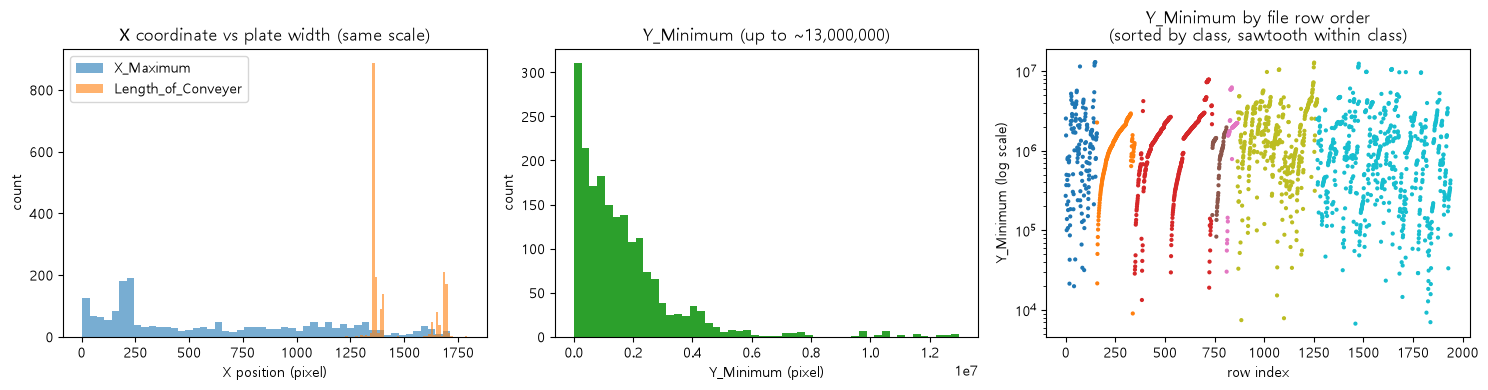

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df["X_Maximum"], bins=50, alpha=0.6, label="X_Maximum")
axes[0].hist(L, bins=50, alpha=0.6, label="Length_of_Conveyer")
axes[0].set_title("X coordinate vs plate width (same scale)")
axes[0].set_xlabel("X position (pixel)"); axes[0].set_ylabel("count")
axes[0].legend()

axes[1].hist(df["Y_Minimum"], bins=50, color="tab:green")
axes[1].set_title("Y_Minimum (up to ~13,000,000)")
axes[1].set_xlabel("Y_Minimum (pixel)"); axes[1].set_ylabel("count")

axes[2].scatter(range(len(df)), df["Y_Minimum"], c=pd.factorize(fault)[0],
                cmap="tab10", s=4)
axes[2].set_yscale("log")
axes[2].set_title("Y_Minimum by file row order\n(sorted by class, sawtooth within class)")
axes[2].set_xlabel("row index"); axes[2].set_ylabel("Y_Minimum (log scale)")
plt.tight_layout()
plt.show()

### 4.2 크기·형태: Perimeter ≥ Δ, 면적 ≤ Δx·Δy

근거: 모든 점이 y = x 선 위(또는 아래)에 있음, 전체 둘레라면 y = 2x 위에 있어야 함

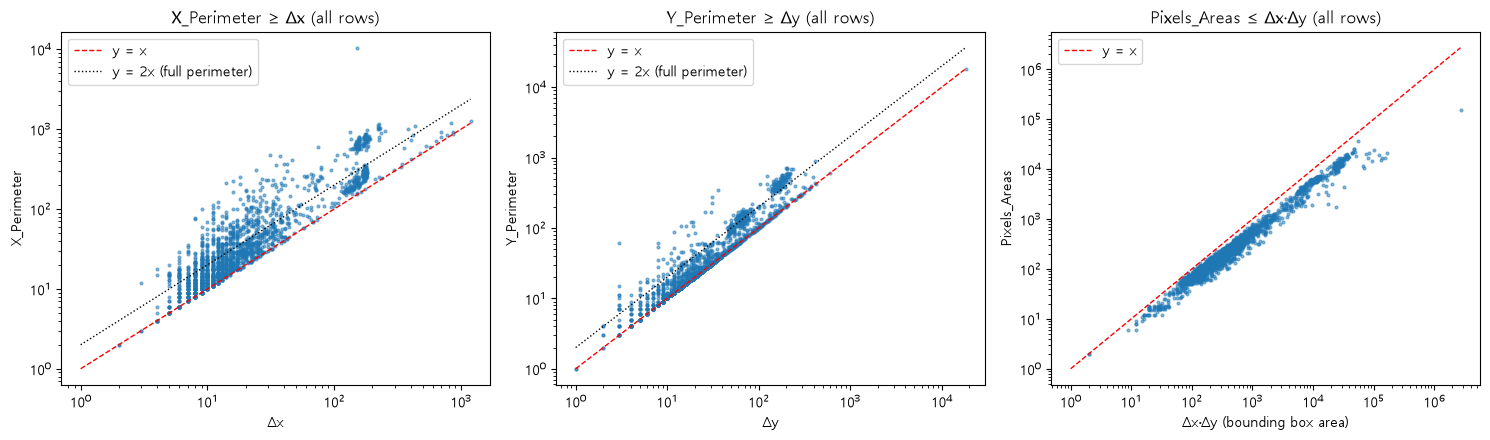

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, d, p, name in [(axes[0], dx, df["X_Perimeter"], "X"),
                       (axes[1], dy, df["Y_Perimeter"], "Y")]:
    ax.scatter(d, p, s=4, alpha=0.5)
    add_diag(ax, 1, d.max())
    add_diag(ax, 1, d.max(), k=2, label="y = 2x (full perimeter)", style="k:")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"Δ{name.lower()}"); ax.set_ylabel(f"{name}_Perimeter")
    ax.set_title(f"{name}_Perimeter ≥ Δ{name.lower()} (all rows)")
    ax.legend()

axes[2].scatter(box, df["Pixels_Areas"], s=4, alpha=0.5)
add_diag(axes[2], 1, box.max())
axes[2].set_xscale("log"); axes[2].set_yscale("log")
axes[2].set_xlabel("Δx·Δy (bounding box area)"); axes[2].set_ylabel("Pixels_Areas")
axes[2].set_title("Pixels_Areas ≤ Δx·Δy (all rows)")
axes[2].legend()
plt.tight_layout()
plt.show()

### 4.3 밝기: 0~255 회색조

근거: 최소·최대 밝기가 0~255 안, Luminosity_Index의 기준 128 = 중간값

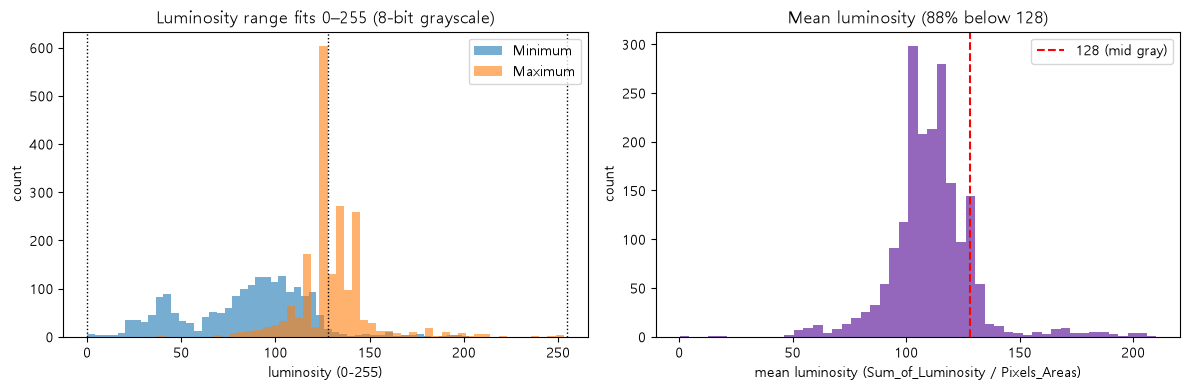

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["Minimum_of_Luminosity"], bins=50, alpha=0.6, label="Minimum")
axes[0].hist(df["Maximum_of_Luminosity"], bins=50, alpha=0.6, label="Maximum")
for v in (0, 128, 255):
    axes[0].axvline(v, color="k", ls=":", lw=1)
axes[0].set_title("Luminosity range fits 0–255 (8-bit grayscale)")
axes[0].set_xlabel("luminosity (0-255)"); axes[0].set_ylabel("count")
axes[0].legend()

mean_lum = df["Sum_of_Luminosity"] / df["Pixels_Areas"]
axes[1].hist(mean_lum, bins=50, color="tab:purple")
axes[1].axvline(128, color="r", ls="--", label="128 (mid gray)")
axes[1].set_title("Mean luminosity (88% below 128)")
axes[1].set_xlabel("mean luminosity (Sum_of_Luminosity / Pixels_Areas)"); axes[1].set_ylabel("count")
axes[1].legend()
plt.tight_layout()
plt.show()

### 4.4 강판·공정 정보

근거: L은 몇 개 값에 몰림(규격 폭), X_Maximum ≤ L, 강종은 원-핫이고 클래스와 강하게 연관

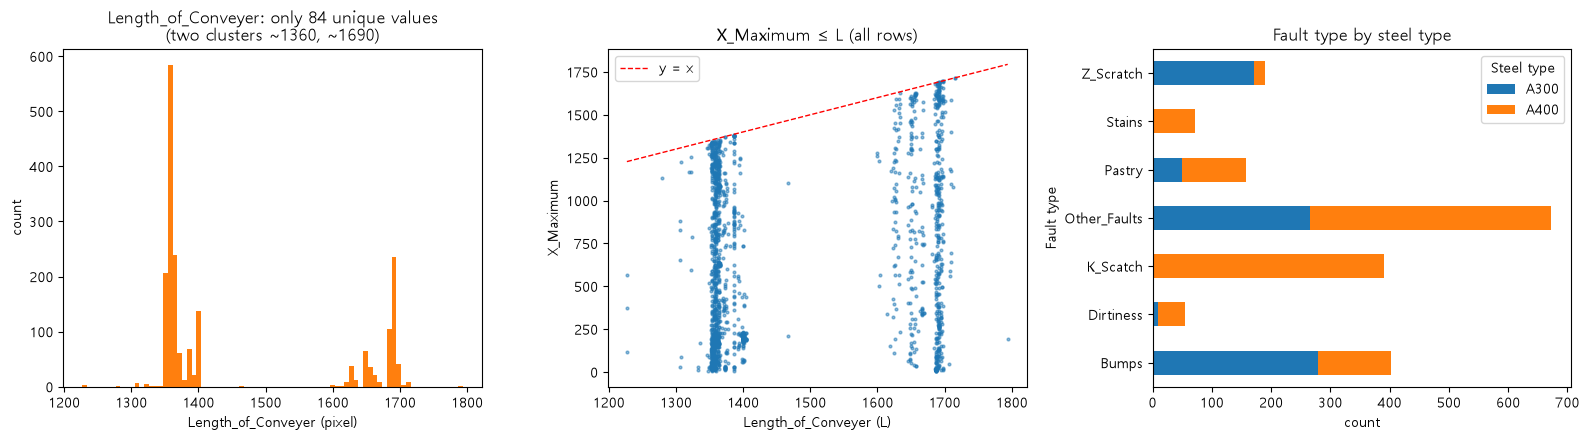

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(L, bins=80, color="tab:orange")
axes[0].set_title(f"Length_of_Conveyer: only {L.nunique()} unique values\n(two clusters ~1360, ~1690)")
axes[0].set_xlabel("Length_of_Conveyer (pixel)"); axes[0].set_ylabel("count")

axes[1].scatter(L, df["X_Maximum"], s=4, alpha=0.5)
add_diag(axes[1], L.min(), L.max())
axes[1].set_xlabel("Length_of_Conveyer (L)"); axes[1].set_ylabel("X_Maximum")
axes[1].set_title("X_Maximum ≤ L (all rows)")
axes[1].legend()

ct = pd.crosstab(fault, df["TypeOfSteel_A300"].map({1: "A300", 0: "A400"}))
ct.plot(kind="barh", stacked=True, ax=axes[2])
axes[2].set_title("Fault type by steel type")
axes[2].set_ylabel("Fault type")      # row_0 → Fault type
axes[2].set_xlabel("count")
axes[2].legend(title="Steel type")    # 범례 제목 TypeOfSteel_A300 → Steel type
plt.tight_layout()
plt.show()

### 4.5 파생 지표 13개: 계산값 vs 원본

근거: 모든 점이 y = x 선 위에 정확히 놓임

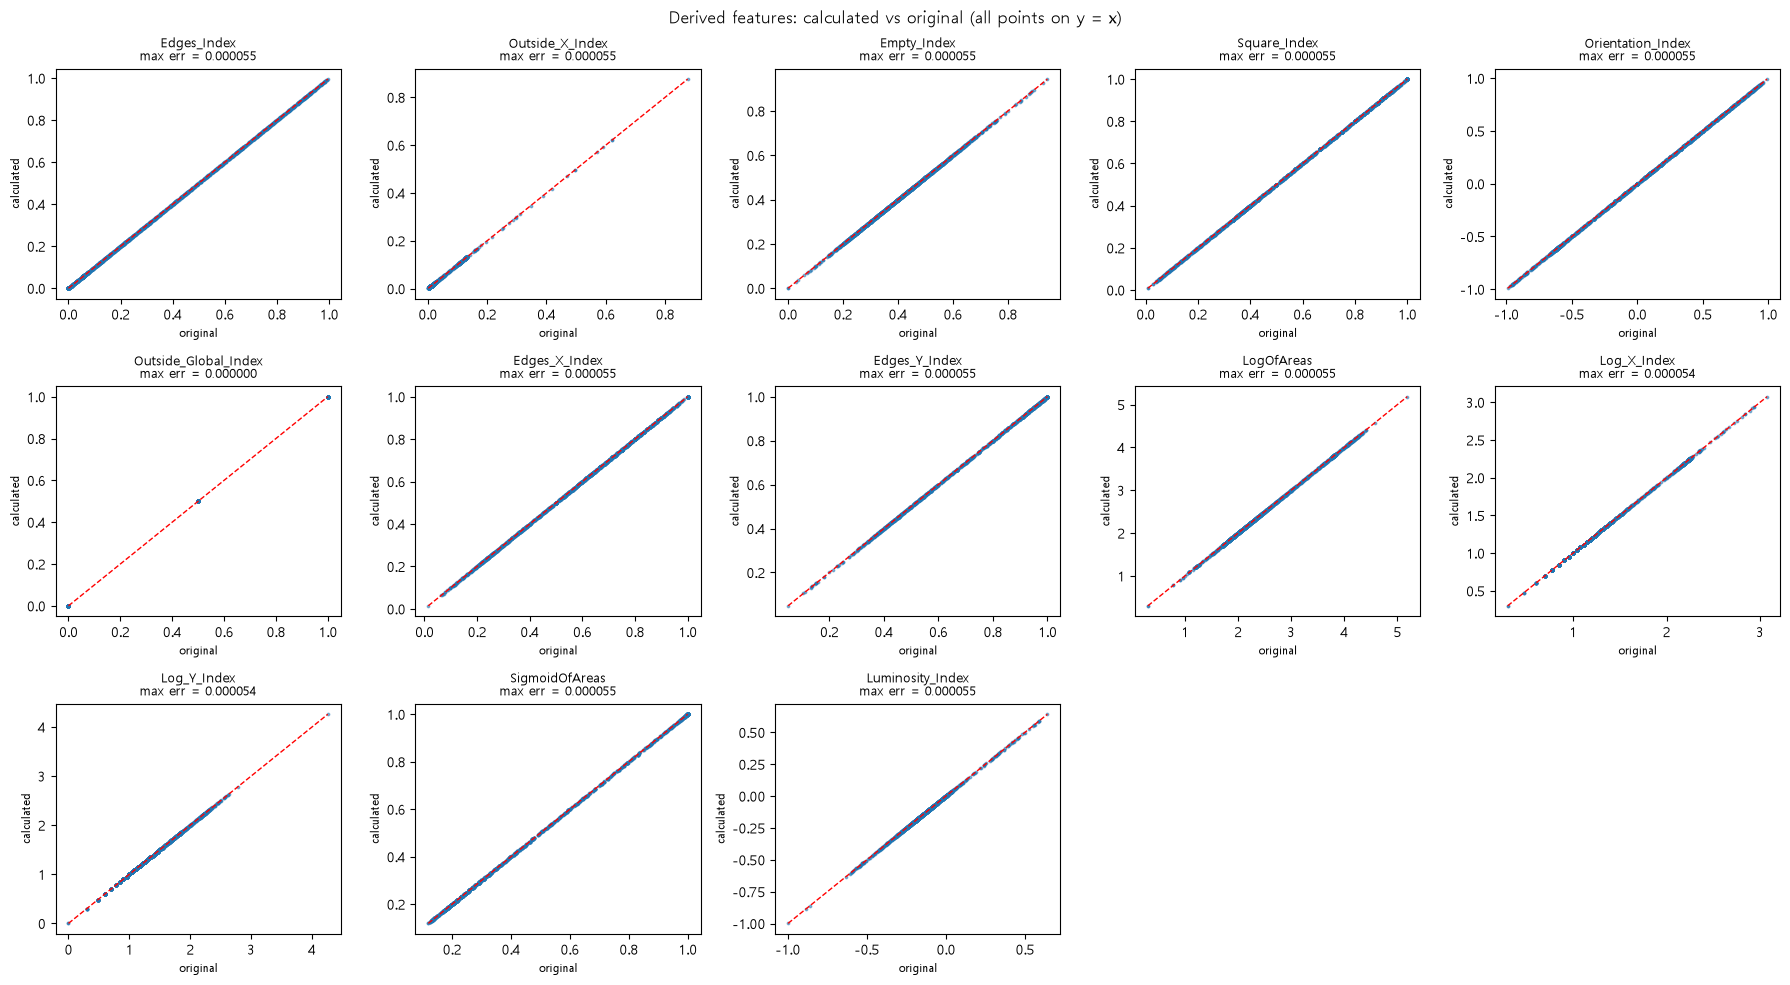

In [42]:
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
for ax, (name, c) in zip(axes.flat, calc.items()):
    orig = df[name]
    err = np.abs(np.asarray(c) - orig).max()
    ax.scatter(orig, c, s=3, alpha=0.5)
    add_diag(ax, orig.min(), orig.max(), label=None)
    ax.set_title(f"{name}\nmax err = {err:.6f}", fontsize=9)
    ax.set_xlabel("original", fontsize=8); ax.set_ylabel("calculated", fontsize=8)
for ax in axes.flat[len(calc):]:
    ax.axis("off")
plt.suptitle("Derived features: calculated vs original (all points on y = x)")
plt.tight_layout()
plt.show()

### 4.6 SigmoidOfAreas: 면적이 아니라 bounding box 넓이의 함수

근거: Pixels_Areas 기준으로는 같은 x에 여러 y(흩어짐), Δx·Δy 기준으로는 하나의 S자 곡선

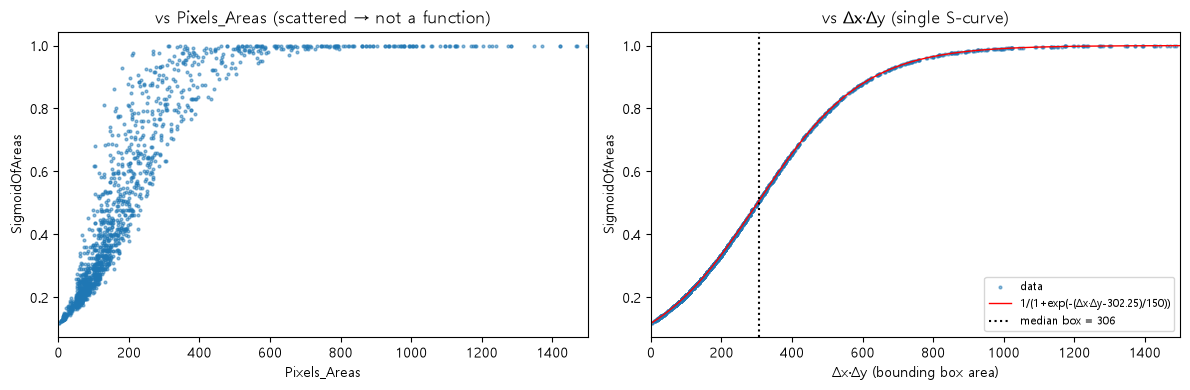

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(df["Pixels_Areas"], df["SigmoidOfAreas"], s=4, alpha=0.5)
axes[0].set_xlim(0, 1500)
axes[0].set_title("vs Pixels_Areas (scattered → not a function)")
axes[0].set_xlabel("Pixels_Areas"); axes[0].set_ylabel("SigmoidOfAreas")

order = np.argsort(box.values)
axes[1].scatter(box, df["SigmoidOfAreas"], s=4, alpha=0.5, label="data")
axes[1].plot(box.values[order], calc["SigmoidOfAreas"].values[order], "r-", lw=1,
             label="1/(1+exp(-(Δx·Δy-302.25)/150))")
axes[1].axvline(box.median(), color="k", ls=":", label=f"median box = {box.median():.0f}")
axes[1].set_xlim(0, 1500)
axes[1].set_title("vs Δx·Δy (single S-curve)")
axes[1].set_xlabel("Δx·Δy (bounding box area)"); axes[1].set_ylabel("SigmoidOfAreas")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 4.7 로그 변환 전후 분포

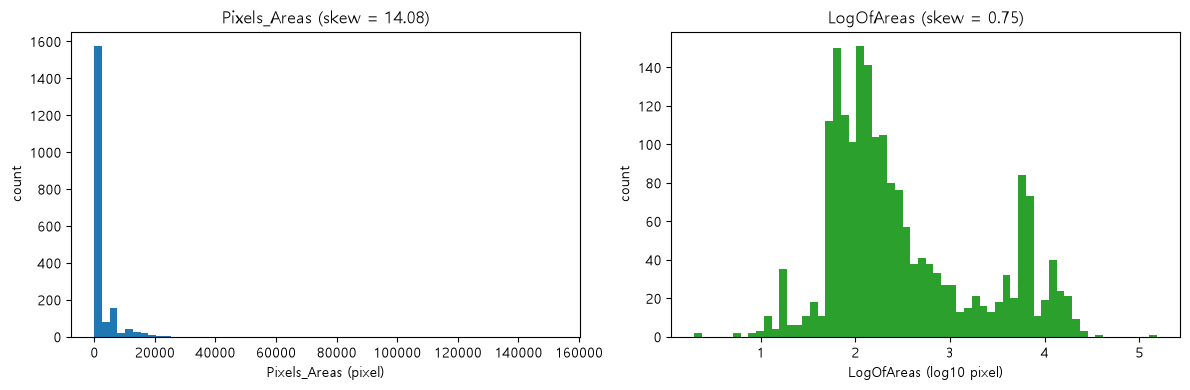

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["Pixels_Areas"], bins=60)
axes[0].set_title(f"Pixels_Areas (skew = {df['Pixels_Areas'].skew():.2f})")
axes[0].set_xlabel("Pixels_Areas (pixel)"); axes[0].set_ylabel("count")
axes[1].hist(df["LogOfAreas"], bins=60, color="tab:green")
axes[1].set_title(f"LogOfAreas (skew = {df['LogOfAreas'].skew():.2f})")
axes[1].set_xlabel("LogOfAreas (log10 pixel)"); axes[1].set_ylabel("count")
plt.tight_layout()
plt.show()

### 4.8 변수 간 중복 관계

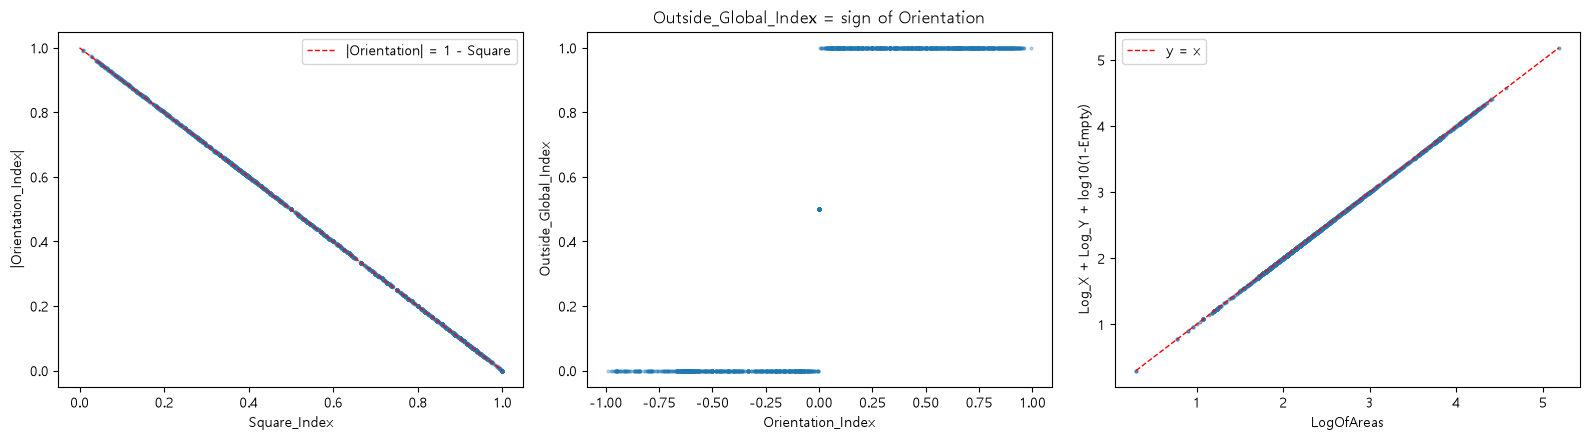

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(df["Square_Index"], df["Orientation_Index"].abs(), s=4, alpha=0.5)
axes[0].plot([0, 1], [1, 0], "r--", lw=1, label="|Orientation| = 1 - Square")
axes[0].set_xlabel("Square_Index"); axes[0].set_ylabel("|Orientation_Index|")
axes[0].legend()

axes[1].scatter(df["Orientation_Index"], df["Outside_Global_Index"], s=4, alpha=0.3)
axes[1].set_xlabel("Orientation_Index"); axes[1].set_ylabel("Outside_Global_Index")
axes[1].set_title("Outside_Global_Index = sign of Orientation")

rhs = df["Log_X_Index"] + df["Log_Y_Index"] + np.log10(1 - df["Empty_Index"])
axes[2].scatter(df["LogOfAreas"], rhs, s=4, alpha=0.5)
add_diag(axes[2], df["LogOfAreas"].min(), df["LogOfAreas"].max())
axes[2].set_xlabel("LogOfAreas"); axes[2].set_ylabel("Log_X + Log_Y + log10(1-Empty)")
axes[2].legend()
plt.tight_layout()
plt.show()

## 5. 정리

- 파생 지표 13개의 계산식과 원본 측정값 6개 항목의 성질을 1,941행 전체에서 확인했다.
- 일부 변수는 서로 완전히 계산 가능한 관계(중복)이므로, 모델링 단계에서 변수 선택·다중공선성 확인 시 참고한다.